# Dataset Initialization

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("diabetes_012_health_indicators_BRFSS2015.csv")

print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nTarget distribution:")
print(df["Diabetes_012"].value_counts().sort_index())

print("\nTarget percentages:")
print(
    (df["Diabetes_012"].value_counts(normalize=True).sort_index() * 100)
    .round(2)
)

print("\nMissing values:", df.isnull().sum().sum())

Dataset shape: (253680, 22)

Columns:
['Diabetes_012', 'HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']

Target distribution:
Diabetes_012
0.0    213703
1.0      4631
2.0     35346
Name: count, dtype: int64

Target percentages:
Diabetes_012
0.0    84.24
1.0     1.83
2.0    13.93
Name: proportion, dtype: float64

Missing values: 0


In [2]:
print("Unique target values:", sorted(df["Diabetes_012"].unique()))

print("Number of features:", df.drop(columns=["Diabetes_012"]).shape[1])

print("Duplicate rows:", df.duplicated().sum())

print(df.dtypes.value_counts())

Unique target values: [np.float64(0.0), np.float64(1.0), np.float64(2.0)]
Number of features: 21
Duplicate rows: 23899
float64    22
Name: count, dtype: int64


# Dataset Analysis

In [3]:
# Use the Kaggle target: 0 = no diabetes, 1 = prediabetes, 2 = diabetes
X = df.drop(columns=["Diabetes_012"])
y = df["Diabetes_012"]

# Check the dimensions of the datasets
print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("\nFeature columns:")
print(X.columns.tolist())
print("\nTarget column:")
print(y.name)
display(X.head())
display(y.head())

Features shape: (253680, 21)
Target shape: (253680,)

Feature columns:
['HighBP', 'HighChol', 'CholCheck', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'HvyAlcoholConsump', 'AnyHealthcare', 'NoDocbcCost', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age', 'Education', 'Income']

Target column:
Diabetes_012


,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,1.0,...,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,0.0,...,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,0.0,...,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,1.0,...,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


0    0.0
1    0.0
2    0.0
3    0.0
4    0.0
Name: Diabetes_012, dtype: float64

In [4]:
# Counts
print(y.value_counts().sort_index())
print(y.value_counts(normalize=True).sort_index() * 100)

Diabetes_012
0.0    213703
1.0      4631
2.0     35346
Name: count, dtype: int64
Diabetes_012
0.0    84.241170
1.0     1.825528
2.0    13.933302
Name: proportion, dtype: float64


In [5]:
# Data types and non-null counts
X.info()

# Check missing values in features
print("\nMissing values in X:")
print(X.isnull().sum().sum())

# Check missing values in target
print("\nMissing values in y:")
print(y.isnull().sum().sum())

<class 'pandas.DataFrame'>
RangeIndex: 253680 entries, 0 to 253679
Data columns (total 21 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   HighBP                253680 non-null  float64
 1   HighChol              253680 non-null  float64
 2   CholCheck             253680 non-null  float64
 3   BMI                   253680 non-null  float64
 4   Smoker                253680 non-null  float64
 5   Stroke                253680 non-null  float64
 6   HeartDiseaseorAttack  253680 non-null  float64
 7   PhysActivity          253680 non-null  float64
 8   Fruits                253680 non-null  float64
 9   Veggies               253680 non-null  float64
 10  HvyAlcoholConsump     253680 non-null  float64
 11  AnyHealthcare         253680 non-null  float64
 12  NoDocbcCost           253680 non-null  float64
 13  GenHlth               253680 non-null  float64
 14  MentHlth              253680 non-null  float64
 15  PhysHlth   

In [6]:
display(X.describe().T)

,count,mean,std,min,25%,50%,75%,max
HighBP,253680.0,0.429001,0.494934,0.0,0.0,0.0,1.0,1.0
HighChol,253680.0,0.424121,0.494210,0.0,0.0,0.0,1.0,1.0
CholCheck,253680.0,0.962670,0.189571,0.0,1.0,1.0,1.0,1.0
BMI,253680.0,28.382364,6.608694,12.0,24.0,27.0,31.0,98.0
Smoker,253680.0,0.443169,0.496761,0.0,0.0,0.0,1.0,1.0
Stroke,253680.0,0.040571,0.197294,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,253680.0,0.094186,0.292087,0.0,0.0,0.0,0.0,1.0
PhysActivity,253680.0,0.756544,0.429169,0.0,1.0,1.0,1.0,1.0
Fruits,253680.0,0.634256,0.481639,0.0,0.0,1.0,1.0,1.0
Veggies,253680.0,0.811420,0.391175,0.0,1.0,1.0,1.0,1.0


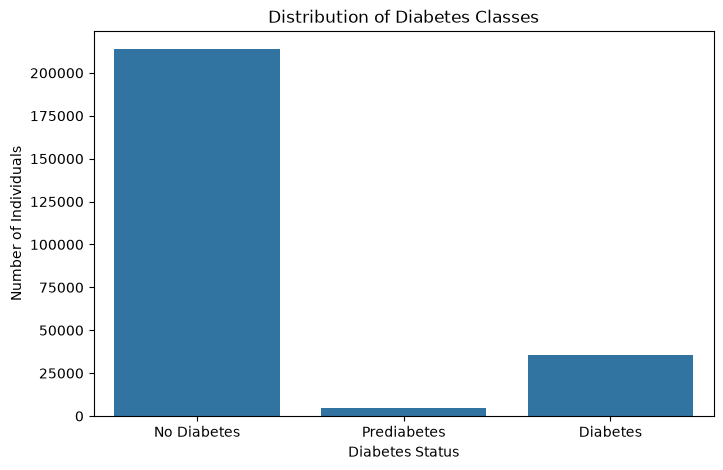

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

target_column = y.name
class_counts = y.value_counts().sort_index()
class_names = {0: "No Diabetes", 1: "Prediabetes", 2: "Diabetes"}

plt.figure(figsize=(8, 5))
sns.barplot(x=[class_names[int(i)] for i in class_counts.index], y=class_counts.values)
plt.title("Distribution of Diabetes Classes")
plt.xlabel("Diabetes Status")
plt.ylabel("Number of Individuals")
plt.show()

In [8]:
# Examine the unique values of every feature
for column in X.columns:
    print(f"\n{column}")
    print(sorted(X[column].unique()))


HighBP
[np.float64(0.0), np.float64(1.0)]

HighChol
[np.float64(0.0), np.float64(1.0)]

CholCheck
[np.float64(0.0), np.float64(1.0)]

BMI
[np.float64(12.0), np.float64(13.0), np.float64(14.0), np.float64(15.0), np.float64(16.0), np.float64(17.0), np.float64(18.0), np.float64(19.0), np.float64(20.0), np.float64(21.0), np.float64(22.0), np.float64(23.0), np.float64(24.0), np.float64(25.0), np.float64(26.0), np.float64(27.0), np.float64(28.0), np.float64(29.0), np.float64(30.0), np.float64(31.0), np.float64(32.0), np.float64(33.0), np.float64(34.0), np.float64(35.0), np.float64(36.0), np.float64(37.0), np.float64(38.0), np.float64(39.0), np.float64(40.0), np.float64(41.0), np.float64(42.0), np.float64(43.0), np.float64(44.0), np.float64(45.0), np.float64(46.0), np.float64(47.0), np.float64(48.0), np.float64(49.0), np.float64(50.0), np.float64(51.0), np.float64(52.0), np.float64(53.0), np.float64(54.0), np.float64(55.0), np.float64(56.0), np.float64(57.0), np.float64(58.0), np.float64(59.

In [9]:
# Combine features and target into one DataFrame
df = X.copy()
df["Diabetes_012"] = y
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
HighBP,253680.0,0.429001,0.494934,0.0,0.0,0.0,1.0,1.0
HighChol,253680.0,0.424121,0.494210,0.0,0.0,0.0,1.0,1.0
CholCheck,253680.0,0.962670,0.189571,0.0,1.0,1.0,1.0,1.0
BMI,253680.0,28.382364,6.608694,12.0,24.0,27.0,31.0,98.0
Smoker,253680.0,0.443169,0.496761,0.0,0.0,0.0,1.0,1.0
Stroke,253680.0,0.040571,0.197294,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,253680.0,0.094186,0.292087,0.0,0.0,0.0,0.0,1.0
PhysActivity,253680.0,0.756544,0.429169,0.0,1.0,1.0,1.0,1.0
Fruits,253680.0,0.634256,0.481639,0.0,0.0,1.0,1.0,1.0
Veggies,253680.0,0.811420,0.391175,0.0,1.0,1.0,1.0,1.0


In [10]:
# Compare feature averages by diabetes status
class_comparison = df.groupby("Diabetes_012").mean().T
class_comparison.columns = ["No Diabetes", "Prediabetes", "Diabetes"]
display(class_comparison)

,No Diabetes,Prediabetes,Diabetes
HighBP,0.371132,0.629022,0.752674
HighChol,0.379171,0.620816,0.670118
CholCheck,0.957104,0.986612,0.993182
BMI,27.742521,30.724466,31.944011
Smoker,0.429680,0.492766,0.518220
Stroke,0.031628,0.057223,0.092457
HeartDiseaseorAttack,0.071833,0.143382,0.222882
PhysActivity,0.779077,0.678471,0.630538
Fruits,0.643023,0.602246,0.585441
Veggies,0.821439,0.768948,0.756408


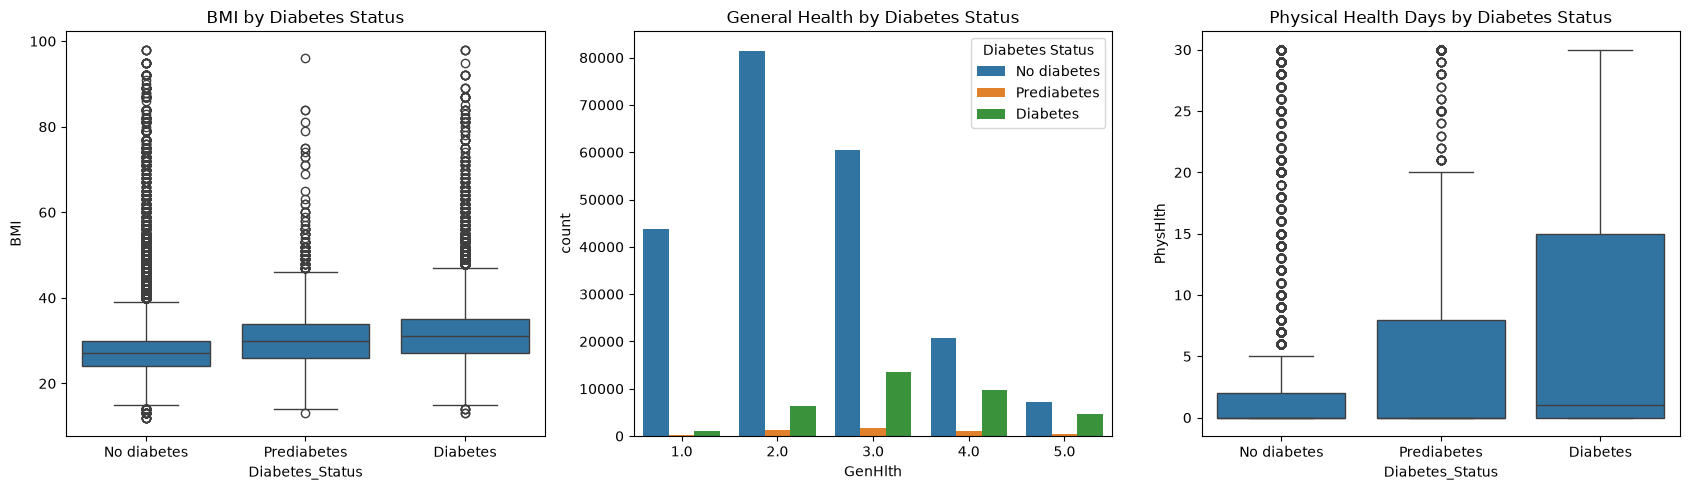

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
class_labels = ["No diabetes", "Prediabetes", "Diabetes"]
plot_df = df.assign(
    Diabetes_Status=df["Diabetes_012"].map(dict(enumerate(class_labels)))
)

sns.boxplot(
    data=plot_df, x="Diabetes_Status", y="BMI", order=class_labels, ax=axes[0]
)
axes[0].set_title("BMI by Diabetes Status")

sns.countplot(
    data=plot_df,
    x="GenHlth",
    hue="Diabetes_Status",
    hue_order=class_labels,
    ax=axes[1]
)
axes[1].set_title("General Health by Diabetes Status")
axes[1].legend(title="Diabetes Status")

sns.boxplot(
    data=plot_df,
    x="Diabetes_Status",
    y="PhysHlth",
    order=class_labels,
    ax=axes[2]
)
axes[2].set_title("Physical Health Days by Diabetes Status")

plt.tight_layout()
plt.show()

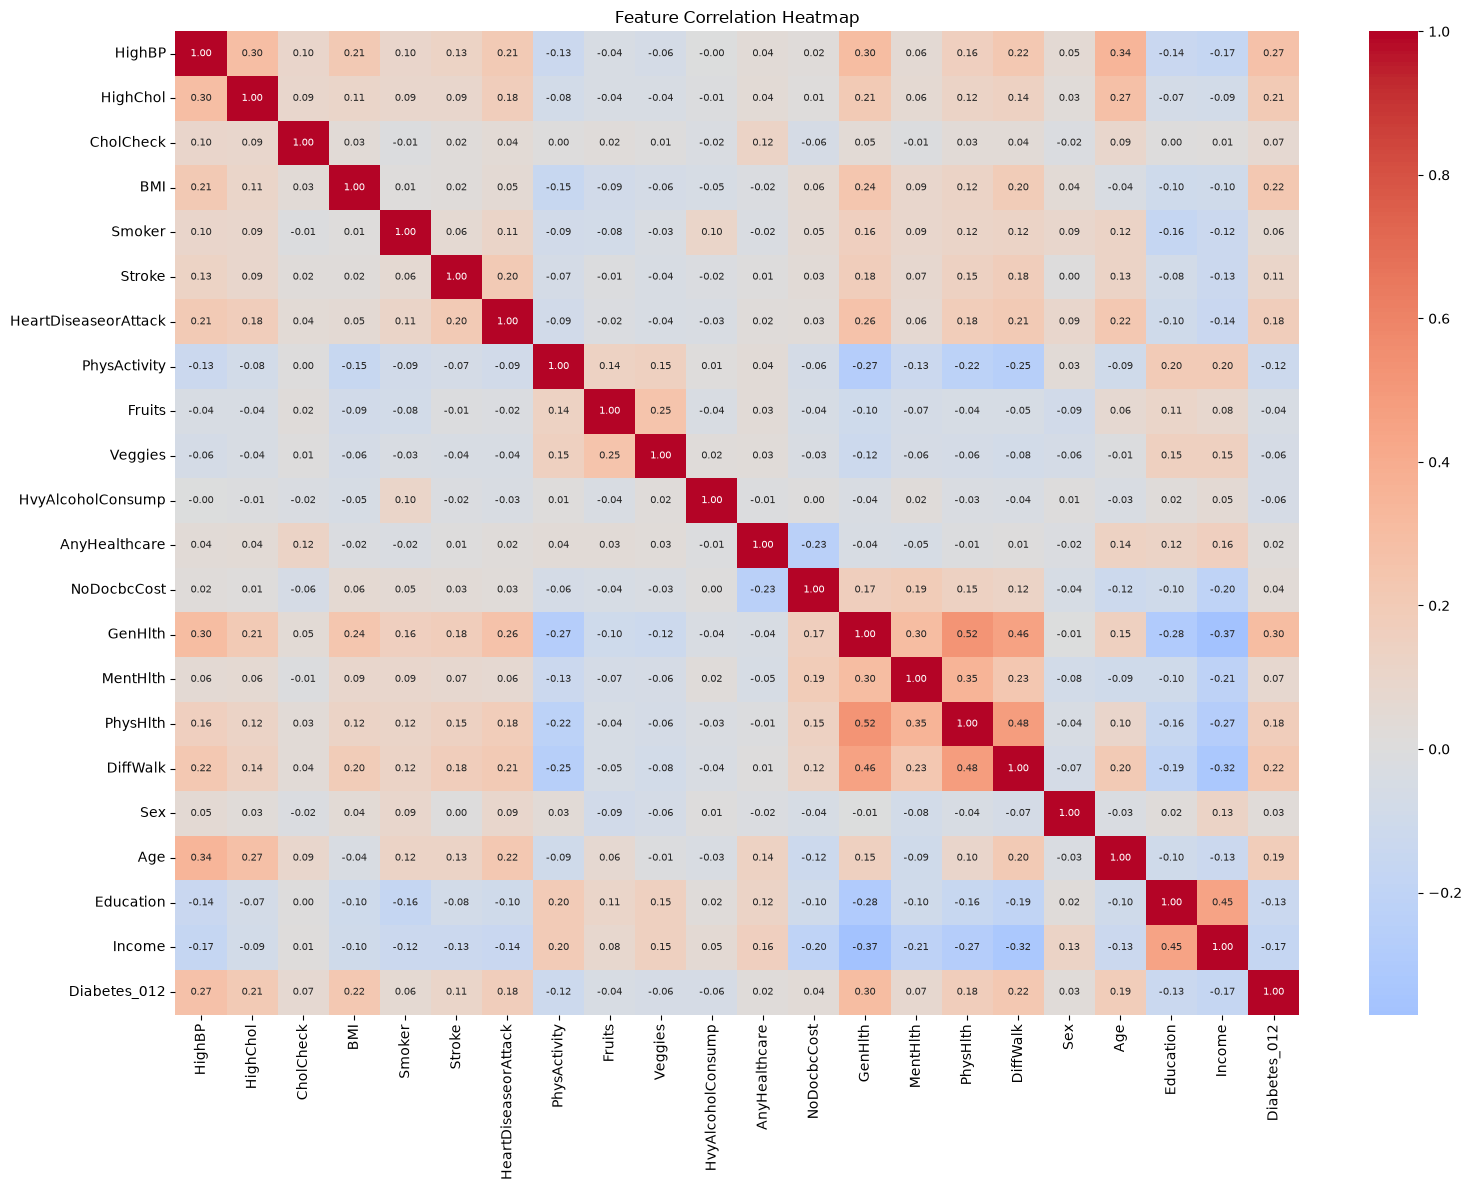

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate correlations
correlation_matrix = df.corr()

# Plot correlation heatmap
plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f",
    annot_kws={"size": 7}
)

plt.title("Feature Correlation Heatmap")
plt.tight_layout()
plt.show()

In [13]:
target_correlations = (
    correlation_matrix["Diabetes_012"]
    .drop("Diabetes_012")
    .sort_values(ascending=False)
)
display(target_correlations)

GenHlth                 0.302587
HighBP                  0.271596
BMI                     0.224379
DiffWalk                0.224239
HighChol                0.209085
Age                     0.185026
HeartDiseaseorAttack    0.180272
PhysHlth                0.176287
Stroke                  0.107179
MentHlth                0.073507
CholCheck               0.067546
Smoker                  0.062914
NoDocbcCost             0.035436
Sex                     0.031040
AnyHealthcare           0.015410
Fruits                 -0.042192
HvyAlcoholConsump      -0.057882
Veggies                -0.058972
PhysActivity           -0.121947
Education              -0.130517
Income                 -0.171483
Name: Diabetes_012, dtype: float64

In [ ]:
from sklearn.model_selection import train_test_split

# Separate features and three-class target
X = df.drop(columns=["Diabetes_012"])
y = df["Diabetes_012"]

# First split: 70% training, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# Second split: divide temporary data into test and validation
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

In [15]:
print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test.shape)

print("\nClass distributions:")

for name, target in [
    ("Training", y_train),
    ("Validation", y_val),
    ("Testing", y_test)
]:
    print(f"\n{name}:")
    print(target.value_counts(normalize=True).sort_index() * 100)

Training: (177576, 21)
Validation: (38052, 21)
Testing: (38052, 21)

Class distributions:

Training:
Diabetes_012
0.0    84.241114
1.0     1.825697
2.0    13.933189
Name: proportion, dtype: float64

Validation:
Diabetes_012
0.0    84.242615
1.0     1.823820
2.0    13.933565
Name: proportion, dtype: float64

Testing:
Diabetes_012
0.0    84.239987
1.0     1.826448
2.0    13.933565
Name: proportion, dtype: float64
